# a3

In [5]:
import numpy as np

In [6]:
x = np.array([0.14, 1.81, 1.38, 1.28, 1.39, 0.80, 0.35, 0.70, 1.40, 0.08, 1.93, 0.79, 1.43, 1.42, 1.68])

In [7]:
x.astype(int)

array([0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1])

In [8]:
def g(t):
    return 2 / (1 + t * t.astype(int))

In [9]:
int(1.1), int(1.5), int(1.99)

(1, 1, 1)

In [10]:
g(x).mean()

np.float64(1.2785186912013606)

# Метод моментів

# 1. Рівномірний розподіл U[0, b]

In [73]:
n = 10000
b = 1

In [74]:
x = np.random.rand(n) * b

In [75]:
b_est = x.mean() + x.std() * 3 ** 0.5

In [76]:
b_est

np.float64(1.0017289059169334)

In [77]:
x.max()

np.float64(0.9997819972252362)

In [78]:
res = []
for i in range(10000):
    x = np.random.rand(n) * b
    b_est = x.mean() + x.std() * 3 ** 0.5
    res.append(x.max() > b_est)
    # if x.max() > b_est:
    #     break

In [79]:
np.array(res).mean()

np.float64(0.4942)

In [80]:
x.max(), x.mean() + x.std() * 3 ** 0.5

(np.float64(0.9998617562514052), np.float64(1.0063022641785393))

In [43]:
# --------------b_est-----------x.max()------

# 2. Gama distribution

In [118]:
n = 100000

a = 3
b = 2

theta = 1 / b
x = np.random.gamma(a, theta, size=n)

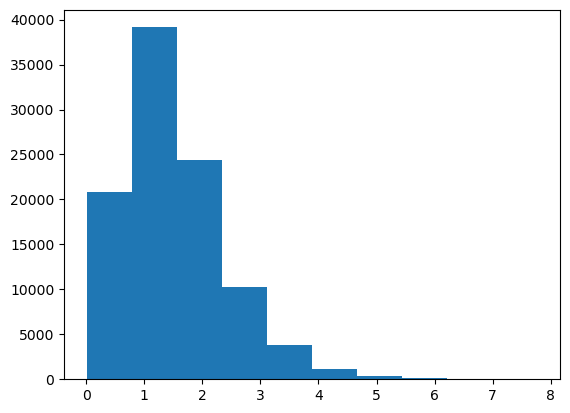

In [119]:
from matplotlib import pyplot as plt
_ = plt.hist(x)

In [120]:
b_est = x.mean() / x.std() ** 2
a_est = x.mean() ** 2 / x.std() ** 2

In [121]:
b, b_est

(2, np.float64(1.9860593621297187))

In [122]:
a, a_est

(3, np.float64(2.9953531763644032))

In [123]:
from tqdm import tqdm

In [133]:

a = 3
b = 2
stat_var_a = []
stat_var_b = []

stat_mean_a = []
stat_mean_b = []

for n in tqdm(range(100, 10001, 100)):
    stats_a = []
    stats_b = []
    for _ in range(4000):
        theta = 1 / b
        x = np.random.gamma(a, theta, size=n)

        b_est = x.mean() / x.std() ** 2
        a_est = x.mean() ** 2 / x.std() ** 2

        stats_a.append(a_est)
        stats_b.append(b_est)
    stat_var_a.append(np.std(stats_a))
    stat_var_b.append(np.std(stats_b))

    stat_mean_a.append(np.mean(stats_a))
    stat_mean_b.append(np.mean(stats_b))

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [02:33<00:00,  1.54s/it]


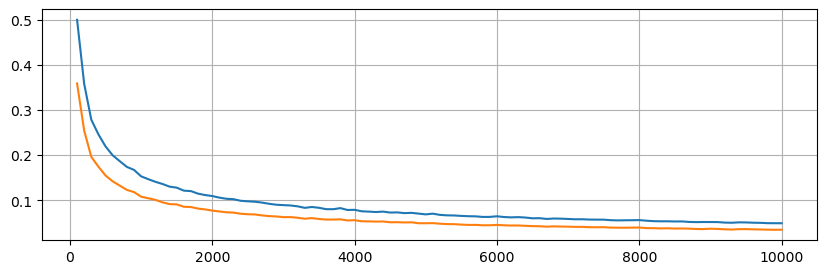

In [134]:
plt.figure(figsize=(10, 3))
plt.plot(range(100, 10001, 100), stat_var_a)
plt.plot(range(100, 10001, 100), stat_var_b)
plt.grid()

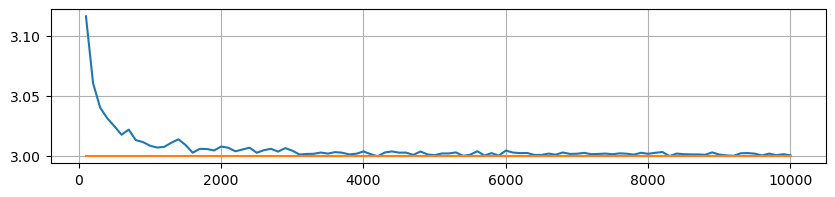

In [135]:
plt.figure(figsize=(10, 2))
plt.plot(range(100, 10001, 100), stat_mean_a, label='mean_est_a')
plt.plot(range(100, 10001, 100), [a] * len(stat_mean_a), label='a')
plt.grid()

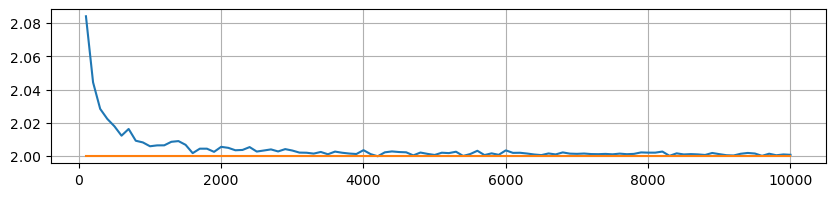

In [136]:
plt.figure(figsize=(10, 2))
plt.plot(range(100, 10001, 100), stat_mean_b, label='mean_est_b')
plt.plot(range(100, 10001, 100), [b] * len(stat_mean_b), label='b')
plt.grid()

# 3. N(m, s^2)

In [138]:

a = 0
b = 2 # variance
stat_var_a = []
stat_var_b = []

stat_mean_a = []
stat_mean_b = []

for n in tqdm(range(100, 10001, 100)):
    stats_a = []
    stats_b = []
    for _ in range(1000):
        theta = 1 / b
        x = np.random.normal(a, b ** 0.5, size=n)

        b_est = x.std() ** 2
        a_est = x.mean()

        stats_a.append(a_est)
        stats_b.append(b_est)
    stat_var_a.append(np.std(stats_a))
    stat_var_b.append(np.std(stats_b))

    stat_mean_a.append(np.mean(stats_a))
    stat_mean_b.append(np.mean(stats_b))

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [00:20<00:00,  4.94it/s]


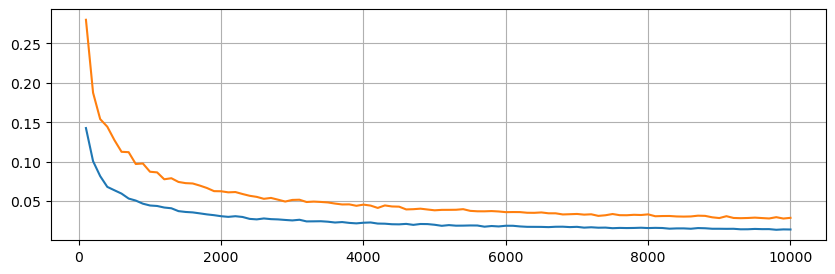

In [139]:
plt.figure(figsize=(10, 3))
plt.plot(range(100, 10001, 100), stat_var_a)
plt.plot(range(100, 10001, 100), stat_var_b)
plt.grid()

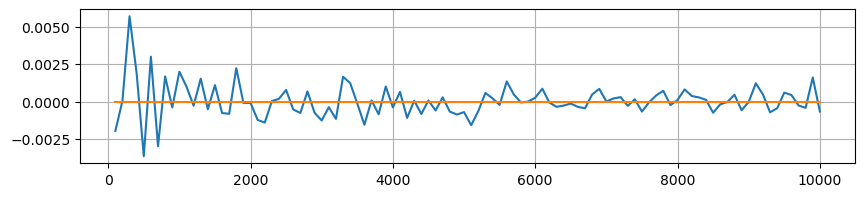

In [140]:
plt.figure(figsize=(10, 2))
plt.plot(range(100, 10001, 100), stat_mean_a, label='mean_est_a')
plt.plot(range(100, 10001, 100), [a] * len(stat_mean_a), label='a')
plt.grid()

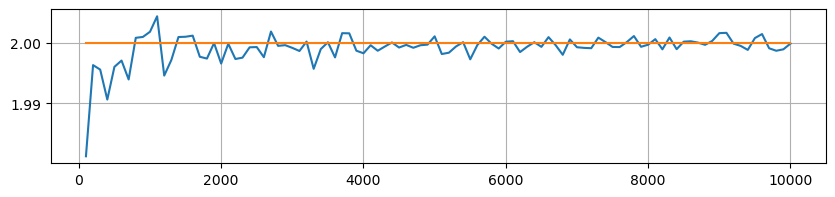

In [141]:
plt.figure(figsize=(10, 2))
plt.plot(range(100, 10001, 100), stat_mean_b, label='mean_est_b')
plt.plot(range(100, 10001, 100), [b] * len(stat_mean_b), label='b')
plt.grid()

# 4 U(G(a), G(b))

In [143]:
from scipy.special import gamma

In [144]:
a = 2.1
b = 3.1

In [161]:
n = 1000
x = np.random.rand(n) * (gamma(b) - gamma(a)) + gamma(a)

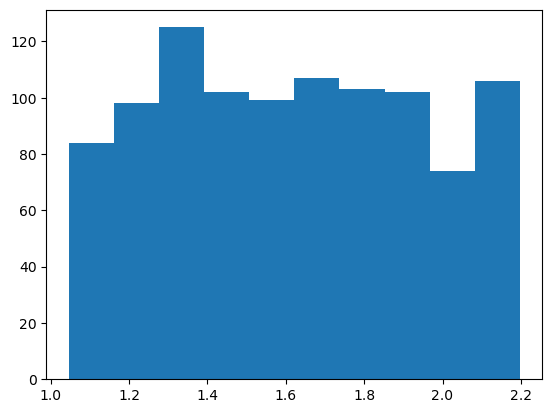

In [162]:
_ = plt.hist(x)

In [163]:
from scipy import optimize

In [172]:
def eq(params):
    a, b = params

    return [
        gamma(a) - (x.mean() - 3 ** 0.5 * x.std()),
        gamma(b) - (x.mean() + 3 ** 0.5 * x.std())
    ]

In [173]:
res = optimize.fsolve(eq, [4, 5])

In [174]:
a, b

(2.1, 3.1)

In [175]:
x.min(), x.max()

(np.float64(1.0465237764076678), np.float64(2.1970990639832477))

In [176]:
gamma(res[0]), gamma(res[1])

(np.float64(1.0523202405376788), np.float64(2.1833011239585476))